# Avance 4. Modelos alternativos
**Proyecto Integrador — Equipo 54 · Fresas Donna y Dream**

**Alcance:** seis regresores individuales (sin ensambles), selección de dos candidatos, búsqueda de hiperparámetros, evaluación agrupada por parcela, comparación inicial/optimizada y elección de un modelo. Los resultados se calculan al ejecutar la libreta: no se inventan métricas.

**Pregunta predictiva primaria:** estimación retrospectiva de `yield_g/planta` a partir de suelo, nutrición foliar, RGB, tratamiento y cultivar. Los otros seis resultados estudiados en el baseline anterior quedan como objetivos científicos secundarios, no se mezclan en la elección de un único modelo final.

**Nota:** la métrica principal de este avance es RMSE, según el nuevo enunciado. MAE y R² son complementarias. El conjunto es pequeño (32 filas, 16 parcelas), por lo que las conclusiones serán exploratorias.

## 0. Procedencia y reproducibilidad
Se reconstruye la tabla analítica directamente desde los nueve Excel RAW con la misma lógica del notebook anterior. Se confirman los tratamientos T1=Compost, T2=N-rich, T3=RCW-HD/WR-HD y T4=RCW-LD. Las parcelas se agrupan mediante `Treatment + Replicate`; las observaciones Donna/Dream de una misma parcela nunca deben quedar en folds distintos.

In [1]:
# Librerías y configuración general
from pathlib import Path
import re, warnings, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from scipy.stats import spearmanr, skew, shapiro, levene, f_oneway, kruskal
from statsmodels.stats.multitest import multipletests

pd.set_option('display.max_columns', 140)
pd.set_option('display.width', 190)
sns.set_theme(style='whitegrid', palette='deep')

SEED = 54
np.random.seed(SEED)

# Detectar raíz del repositorio aunque Jupyter se abra desde notebook/.
HERE = Path.cwd().resolve()

ROOT = HERE
BASE_DIR = HERE

OUT = HERE / 'outputs' / 'avance4_modelado'
FIG = OUT / 'figuras'

OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

FILES = {
    'antiox': 'Antiox_data.xlsx',
    'sampling': 'Sampling May 2023.xlsx',
    'harvests': 'harvests.xlsx',
    'soil': 'Dataset_final_suelo.xlsx',
    'leaf': 'Dataset_final_leaf.xlsx',
    'poly_raw': 'alldata_polyphenols.xlsx',
    'anth_raw': 'Anthocyanins.xlsx',
    'vitc_raw': 'VitC_MarinaPerez.xlsx',
    'poly_table': 'Table polyphenols.xlsx',
}

missing_files = [name for name in FILES.values() if not (BASE_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(
        f'Faltan archivos en {BASE_DIR}: ' + ', '.join(missing_files)
    )

print('Raíz del repositorio:', ROOT)
print('Directorio RAW:', BASE_DIR)
print('Archivos originales detectados:', len(FILES))
print('Resultados:', OUT)

Raíz del repositorio: C:\Users\joaqu\OneDrive\Documentos\02. Maestría Tec\8° Trimestre\Proyecto Integrador
Directorio RAW: C:\Users\joaqu\OneDrive\Documentos\02. Maestría Tec\8° Trimestre\Proyecto Integrador
Archivos originales detectados: 9
Resultados: C:\Users\joaqu\OneDrive\Documentos\02. Maestría Tec\8° Trimestre\Proyecto Integrador\outputs\avance4_modelado


In [2]:
SHEETS = {
    'antiox': {'Antiox_data': None},
    'sampling': {'all_data': None},
    'harvests': {'harvests': None, 'productions_kg': None},
    'soil': {'Final': None},
    'leaf': {'Isotopes': None, 'RGB': None, 'Nitrates': None, 'Nutrients': 1},
    'poly_raw': {'alldata_polyphenols': None, 'data_polyphenols': None},
    'anth_raw': {'Cyanidin gluc': None, 'Pelargonidin gluc': None, 'Pelargonidin rutin': None},
    'vitc_raw': {'Hoja3': None},
}

inventory=[]
for key, name in FILES.items():
    book = pd.ExcelFile(BASE_DIR / name)
    for sheet in book.sheet_names:
        inventory.append({'Fuente':key,'Archivo':name,'Hoja':sheet})
    if key in SHEETS:
        for sheet in SHEETS[key]:
            if sheet not in book.sheet_names:
                raise ValueError(f'{name}: falta hoja {sheet!r}. Hojas disponibles: {book.sheet_names}')

inventory_df = pd.DataFrame(inventory)
raw={}
for key, sheets in SHEETS.items():
    for sheet, header in sheets.items():
        args={'sheet_name':sheet}
        if header is not None:
            args['header']=header
        df=pd.read_excel(BASE_DIR / FILES[key], **args)
        df.columns=[str(c).strip() for c in df.columns]
        raw[(key,sheet)] = df
        inventory_df.loc[(inventory_df.Fuente==key)&(inventory_df.Hoja==sheet),'Filas']=len(df)
        inventory_df.loc[(inventory_df.Fuente==key)&(inventory_df.Hoja==sheet),'Columnas']=df.shape[1]

display(inventory_df.loc[inventory_df['Filas'].notna(), ['Fuente','Archivo','Hoja','Filas','Columnas']])


,Fuente,Archivo,Hoja,Filas,Columnas
0,antiox,Antiox_data.xlsx,Antiox_data,32.0,27.0
8,sampling,Sampling May 2023.xlsx,all_data,32.0,19.0
10,harvests,harvests.xlsx,harvests,608.0,13.0
12,harvests,harvests.xlsx,productions_kg,32.0,18.0
16,soil,Dataset_final_suelo.xlsx,Final,32.0,15.0
18,leaf,Dataset_final_leaf.xlsx,Nitrates,65.0,14.0
19,leaf,Dataset_final_leaf.xlsx,Isotopes,64.0,9.0
20,leaf,Dataset_final_leaf.xlsx,RGB,96.0,8.0
21,leaf,Dataset_final_leaf.xlsx,Nutrients,64.0,28.0
22,poly_raw,alldata_polyphenols.xlsx,alldata_polyphenols,64.0,20.0


In [3]:
antiox_raw = raw[('antiox','Antiox_data')]
fruit_raw = raw[('sampling','all_data')]
harvest_raw = raw[('harvests','harvests')]
yield_raw = raw[('harvests','productions_kg')]
soil_raw = raw[('soil','Final')]
iso_raw = raw[('leaf','Isotopes')]
rgb_raw = raw[('leaf','RGB')]
nitr_raw = raw[('leaf','Nitrates')]
nut_raw = raw[('leaf','Nutrients')].copy()
nut_raw = nut_raw.loc[:, ~nut_raw.columns.astype(str).str.startswith('Unnamed')]
nitr_raw = nitr_raw.loc[nitr_raw['Parcel/Plot'].notna()].copy()

CORE = {
    'Antioxidantes':antiox_raw, 'Calidad fruto':fruit_raw, 'Producción':yield_raw,
    'Cosechas por fecha':harvest_raw, 'Suelo':soil_raw, 'Hoja isótopos':iso_raw,
    'Hoja nitratos':nitr_raw, 'Hoja nutrientes':nut_raw, 'Hoja RGB':rgb_raw
}

def describe_source(name, df):
    return {
        'Fuente':name, 'Filas':len(df), 'Columnas':df.shape[1],
        'Numéricas':df.select_dtypes(include=np.number).shape[1],
        'NA totales':int(df.isna().sum().sum()),
        'Filas idénticas':int(df.duplicated().sum())
    }

source_profile = pd.DataFrame([describe_source(k,d) for k,d in CORE.items()])
display(source_profile)


,Fuente,Filas,Columnas,Numéricas,NA totales,Filas idénticas
0,Antioxidantes,32,27,22,12,0
1,Calidad fruto,32,19,16,14,0
2,Producción,32,18,12,99,0
3,Cosechas por fecha,608,13,8,912,0
4,Suelo,32,15,13,0,0
5,Hoja isótopos,64,9,4,0,0
6,Hoja nitratos,64,14,9,0,0
7,Hoja nutrientes,64,24,20,0,0
8,Hoja RGB,96,8,4,0,0


In [4]:
# Estandarización de tratamientos.
SOIL_TO_T = {
    'COMPOST':'T1', 'N-RICH':'T2', 'NRICH':'T2',
    'RCW-HD':'T3','RWC-HD':'T3','WR-HD':'T3','RCWHD':'T3',
    'RCW-LD':'T4','RWC-LD':'T4','WR-LD':'T4','RCWLD':'T4'
}
# IMPORTANTE: en todos los gráficos/tablas visibles se usarán nombres, no códigos.
T_TO_NAME = {'T1':'Compost', 'T2':'N-rich', 'T3':'RCW-HD', 'T4':'RCW-LD'}
TREATMENT_ORDER = ['Compost','N-rich','RCW-HD','RCW-LD']

def clean_cv(s):
    v=s.astype('string').str.strip().str.upper()
    return v.map({'DO':'Donna','DONA':'Donna','DONNA':'Donna','DR':'Dream','DREAM':'Dream'})

def clean_code(s):
    return s.astype('string').str.strip().str.upper().str.replace(r'\s+','',regex=True)

def require_cols(df, cols, label):
    missing=set(cols)-set(df.columns)
    if missing:
        raise KeyError(f'{label}: columnas no encontradas: {sorted(missing)}; disponibles={list(df.columns)}')

KEYS=['Cultivar','Treatment','Replicate']

def make_keys(df, cv, tr, rep, label):
    require_cols(df,[cv,tr,rep],label)
    return pd.DataFrame({
        'Cultivar':clean_cv(df[cv]),
        'Treatment':clean_code(df[tr]),
        'Replicate':clean_code(df[rep])
    }, index=df.index)

def check_unique(df, keys, label):
    na=df[keys].isna().any(axis=1)
    dup=df.duplicated(keys,keep=False)
    if na.any() or dup.any():
        display(df.loc[na|dup,keys].head(20))
        raise ValueError(f'{label}: claves nulas o duplicadas; no se realizará unión insegura.')

display(pd.DataFrame([{'Código original':k,'Tratamiento mostrado':v} for k,v in T_TO_NAME.items()]))


,Código original,Tratamiento mostrado
0,T1,Compost
1,T2,N-rich
2,T3,RCW-HD
3,T4,RCW-LD


In [5]:
# Construcción de las fuentes principales en Cultivar × Treatment × Replicate.
ant = make_keys(antiox_raw,'cultivar','Treatment','Replicate','Antiox_data')
for c in antiox_raw.columns:
    if c not in ['Sample','cultivar','Treatment','Replicate','New_block']:
        ant[c]=pd.to_numeric(antiox_raw[c],errors='coerce')
check_unique(ant,KEYS,'Antioxidantes')

fruit = make_keys(fruit_raw,'Cv','Treatment','Repl','Sampling/all_data')
for c in ['Weight','Hydrat','Firm','Hue','Chroma','BRIX','Acidity','GA','GGA','CSI']:
    if c in fruit_raw:
        fruit['fruit_'+c]=pd.to_numeric(fruit_raw[c],errors='coerce')
check_unique(fruit,KEYS,'Calidad del fruto')

yld = make_keys(yield_raw,'Cv','Treatment','Repl','Producción')
for c in ['Com Ton/ha','No com Ton/ha','Nº de plantes','g/planta']:
    if c in yield_raw:
        yld['yield_'+c]=pd.to_numeric(yield_raw[c],errors='coerce')
check_unique(yld,KEYS,'Producción')

sets_keys={name:set(map(tuple,df[KEYS].to_numpy())) for name,df in {'Antiox':ant,'Fruto':fruit,'Producción':yld}.items()}
assert sets_keys['Antiox']==sets_keys['Fruto']==sets_keys['Producción'], 'Las claves de las fuentes principales no coinciden.'

# Suelo 2023: una observación por Treatment × Replicate.
require_cols(soil_raw,['Treatment','Block','Year'],'Suelo/Final')
soil23=soil_raw.loc[pd.to_numeric(soil_raw['Year'],errors='coerce').eq(2023)].copy()
soil_t_raw=clean_code(soil23['Treatment']).str.replace('_','-',regex=False)
soil=pd.DataFrame({'Treatment':soil_t_raw.map(SOIL_TO_T), 'Replicate':clean_code(soil23['Block'])}, index=soil23.index)
for c in soil23.columns:
    if c not in ['Treatment','Year','Block','Plot']:
        soil['soil_'+c]=pd.to_numeric(soil23[c],errors='coerce')
if soil.Treatment.isna().any():
    raise ValueError('Existen tratamientos de suelo sin mapear: '+str(soil23.loc[soil.Treatment.isna(),'Treatment'].unique()))
check_unique(soil,['Treatment','Replicate'],'Suelo 2023')

# Hojas: réplicas técnicas en la misma unidad/fecha se resumen por media.
def pivot_leaf(df,cv,tr,rep,time,measures,prefix,label):
    require_cols(df,[cv,tr,rep]+measures,label)
    k=make_keys(df,cv,tr,rep,label)
    k['Time']=pd.Series(time,index=df.index).astype('string').str.strip()
    for c in measures:
        k[c]=pd.to_numeric(df[c],errors='coerce')
    piv=k.pivot_table(index=KEYS, columns='Time', values=measures, aggfunc='mean')
    piv.columns=[f'{prefix}_{str(c)}_{str(t)}' for c,t in piv.columns]
    return piv.reset_index()

iso_t=iso_raw['Date'].astype('string').str.extract('(March|May)',expand=False)
leaf_iso=pivot_leaf(iso_raw,'Cv','Treatment','Replicate',iso_t,
                    [c for c in ['%N','d13C'] if c in iso_raw], 'leaf_iso','Isotopes')

nut_vars=[c for c in nut_raw.columns if c not in ['Sample','Parcel/Plot','Cv','Treatment','Repl','Time']
          and pd.api.types.is_numeric_dtype(nut_raw[c])]
leaf_nut=pivot_leaf(nut_raw,'Cv','Treatment','Repl',nut_raw['Time'],nut_vars,'leaf_nut','Nutrients')
leaf_no3=pivot_leaf(nitr_raw,'Cv','Treatment','Repl',nitr_raw['Time'],
                    [c for c in ['mg NO3-/ g DW','mg NO3-/ 100 mg DW'] if c in nitr_raw],
                    'leaf_no3','Nitrates')
leaf_rgb=pivot_leaf(rgb_raw,'Cv','Treatment','Repl',rgb_raw['Time'],
                    [c for c in ['GA','GGA','CSI'] if c in rgb_raw], 'leaf_rgb','RGB')

# Unión maestra.
ana=ant.merge(fruit,on=KEYS,how='outer',validate='one_to_one',indicator='_source_fruit')
ana=ana.merge(yld,on=KEYS,how='outer',validate='one_to_one',indicator='_source_yield')
ana=ana.merge(soil,on=['Treatment','Replicate'],how='left',validate='many_to_one',indicator='_source_soil')
for x in [leaf_iso,leaf_nut,leaf_no3,leaf_rgb]:
    ana=ana.merge(x,on=KEYS,how='left',validate='one_to_one')

ana['Parcel_ID']=ana['Treatment'].astype(str)+'_'+ana['Replicate'].astype(str)
ana['Treatment_name']=ana['Treatment'].map(T_TO_NAME).fillna('Sin mapear')
ana['Cultivar_Treatment']=ana['Cultivar'].astype(str)+' · '+ana['Treatment_name'].astype(str)

assert not ana[KEYS].duplicated().any(), 'La unión generó llaves duplicadas.'
print('Filas analíticas:',len(ana))
print('Parcelas:',ana.Parcel_ID.nunique())
print('Variables numéricas:',len(ana.select_dtypes(include=np.number).columns))
print('Tratamientos visibles:',sorted(ana.Treatment_name.unique()))

if len(ana)!=32 or ana.Parcel_ID.nunique()!=16:
    warnings.warn('Cobertura distinta de 32 filas / 16 parcelas: revisar fuentes y llaves de unión.')


Filas analíticas: 32
Parcelas: 16
Variables numéricas: 100
Tratamientos visibles: ['Compost', 'N-rich', 'RCW-HD', 'RCW-LD']


In [6]:
# Bloques científicos.
design_cols=['Cultivar','Treatment','Treatment_name','Replicate','Parcel_ID','Cultivar_Treatment']
soil_cols=[c for c in ana if c.startswith('soil_') and pd.api.types.is_numeric_dtype(ana[c])]
leaf_nutrition_cols=[c for c in ana if c.startswith(('leaf_nut_','leaf_iso_','leaf_no3_')) and pd.api.types.is_numeric_dtype(ana[c])]
rgb_cols=[c for c in ana if c.startswith('leaf_rgb_') and pd.api.types.is_numeric_dtype(ana[c])]
production_cols=[c for c in ana if c.startswith('yield_') and pd.api.types.is_numeric_dtype(ana[c])]
rgb_duplicate_outcomes=[c for c in ['fruit_GA','fruit_GGA','fruit_CSI'] if c in ana.columns]
# GA/GGA/CSI del archivo de sampling se consideran indicadores de vegetación/RGB, no calidad fisicoquímica del fruto.
# Además, en el EDA previo se observó que duplican las mediciones RGB de mayo; se excluyen de outcomes para evitar relaciones innecesarias.
physchem_cols=[c for c in ana if c.startswith('fruit_') and pd.api.types.is_numeric_dtype(ana[c]) and c not in rgb_duplicate_outcomes]
nutritional_cols=[c for c in ant.columns if c not in KEYS and c in ana.columns and pd.api.types.is_numeric_dtype(ana[c])]

BLOCKS={
    'Diseño experimental':design_cols,
    'Suelo':soil_cols,
    'Hoja / nutrición':leaf_nutrition_cols,
    'Hoja / RGB-fisiología':rgb_cols,
    'Producción':production_cols,
    'Calidad fisicoquímica':physchem_cols,
    'Calidad nutricional / bioactivos':nutritional_cols,
}
block_summary=pd.DataFrame([{'Bloque':k,'Variables':len(v)} for k,v in BLOCKS.items()])
display(block_summary)

X_raw_cols=soil_cols+leaf_nutrition_cols+rgb_cols
outcome_families={
    'Producción':production_cols,
    'Fisicoquímica':physchem_cols,
    'Nutricional':nutritional_cols,
}

advantages = [
    'Diseño balanceado: 2 cultivares × 4 tratamientos × 4 réplicas.',
    'Múltiples capas del sistema: suelo, hoja, fisiología/RGB, producción y fruto.',
    'Mediciones temporales en suelo y hoja que permiten estudiar evolución.',
    'Resultados químicos y bioactivos suficientes para formular objetivos múltiples.'
]
limitations = [
    'n≈32 es pequeño frente al número de variables (p >> n).',
    'Algunas variables presentan faltantes y distribuciones sesgadas.',
    'Suelo se comparte por parcela; no todas las columnas son observaciones independientes.',
    'Treatment mezcla tipo de enmienda y práctica de labranza; no permite separar ambos efectos causalmente.',
    'Los modelos solo pueden generalizar razonablemente dentro de tratamientos/cultivares similares a los observados.'
]

display(Markdown('### Ventajas de la información\n' + '\n'.join([f'- {x}' for x in advantages])))
display(Markdown('### Limitaciones que condicionan el modelado\n' + '\n'.join([f'- {x}' for x in limitations])))

print('Columnas GA/GGA/CSI excluidas de calidad fisicoquímica por pertenecer a RGB/redundancia:', rgb_duplicate_outcomes)


,Bloque,Variables
0,Diseño experimental,6
1,Suelo,11
2,Hoja / nutrición,44
3,Hoja / RGB-fisiología,9
4,Producción,4
5,Calidad fisicoquímica,7
6,Calidad nutricional / bioactivos,22


### Ventajas de la información
- Diseño balanceado: 2 cultivares × 4 tratamientos × 4 réplicas.
- Múltiples capas del sistema: suelo, hoja, fisiología/RGB, producción y fruto.
- Mediciones temporales en suelo y hoja que permiten estudiar evolución.
- Resultados químicos y bioactivos suficientes para formular objetivos múltiples.

### Limitaciones que condicionan el modelado
- n≈32 es pequeño frente al número de variables (p >> n).
- Algunas variables presentan faltantes y distribuciones sesgadas.
- Suelo se comparte por parcela; no todas las columnas son observaciones independientes.
- Treatment mezcla tipo de enmienda y práctica de labranza; no permite separar ambos efectos causalmente.
- Los modelos solo pueden generalizar razonablemente dentro de tratamientos/cultivares similares a los observados.

Columnas GA/GGA/CSI excluidas de calidad fisicoquímica por pertenecer a RGB/redundancia: ['fruit_GA', 'fruit_GGA', 'fruit_CSI']


## 1. Diagnóstico de la tarea y calidad de los datos
**Regresión**, porque el rendimiento en gramos por planta es continuo. La exploración comprueba faltantes, duplicados, valores extremos y correlación entre predictores; los valores atípicos no se eliminan automáticamente. El análisis no pretende estimar causalidad ni realizar pronóstico anterior a la cosecha.

In [7]:
# Ingeniería temporal: baseline + delta, reutilizando la lógica de Avance 2.
def feature_builder(df):
    z=df.copy(); created={}; removed=[]; original=list(z.columns)

    for family in ['leaf_iso_','leaf_no3_','leaf_nut_']:
        may_cols=[c for c in original if c.startswith(family) and c.endswith('_May')]
        for may in may_cols:
            march=may[:-3]+'March'
            if march in z.columns:
                new='FE_delta_'+may.replace('_May','')
                z[new]=pd.to_numeric(z[may],errors='coerce')-pd.to_numeric(z[march],errors='coerce')
                created[new]=f'Cambio May - March; baseline conservado en {march}.'
                removed.append(may)

    rgb_metrics=sorted({c.rsplit('_',1)[0] for c in original if c.startswith('leaf_rgb_')})
    for base in rgb_metrics:
        dec,mar,may=base+'_December',base+'_March',base+'_May'
        if dec in z and mar in z:
            d1='FE_delta_'+base+'_March_minus_December'
            z[d1]=pd.to_numeric(z[mar],errors='coerce')-pd.to_numeric(z[dec],errors='coerce')
            created[d1]=f'Cambio March - December para {base}; December funciona como baseline.'
            removed.append(mar)
        if mar in z and may in z:
            d2='FE_delta_'+base+'_May_minus_March'
            z[d2]=pd.to_numeric(z[may],errors='coerce')-pd.to_numeric(z[mar],errors='coerce')
            created[d2]=f'Cambio May - March para {base}.'
            removed.append(may)

    removed=list(dict.fromkeys([c for c in removed if c in z.columns]))
    z=z.drop(columns=removed)
    return z,created,removed

ana_fe, derived, temporal_removed = feature_builder(ana)

# Control de disponibilidad temporal (el modo retrospectivo NO equivale a pronostico temprano).
PREDICTION_MODE = 'retrospectivo'  # 'temprano' solo tras verificar calendario de muestreo
CUTOFF_PERIOD = None  # December, March o May si PREDICTION_MODE='temprano'
PERIOD_ORDER = {'December': 0, 'March': 1, 'May': 2}

def latest_measurement_period(column):
    if 'May_minus_March' in column: return 'May'
    if 'March_minus_December' in column: return 'March'
    if column.startswith('FE_delta_leaf_'): return 'May'
    for period in PERIOD_ORDER:
        if column.endswith('_' + period): return period
    return None

if PREDICTION_MODE == 'temprano':
    if CUTOFF_PERIOD not in PERIOD_ORDER:
        raise ValueError('CUTOFF_PERIOD debe ser December, March o May.')
    excluded_temporal = [c for c in ana_fe.columns
                         if latest_measurement_period(c) is not None
                         and PERIOD_ORDER[latest_measurement_period(c)] > PERIOD_ORDER[CUTOFF_PERIOD]]
    ana_fe = ana_fe.drop(columns=excluded_temporal)
    print('Excluidas por corte temporal:', len(excluded_temporal))
    print('Advertencia: revisar tambien fechas reales de suelo y cosecha; el nombre no prueba disponibilidad.')
else:
    excluded_temporal = []
    print('Modo retrospectivo: asociaciones posteriores al cultivo; NO prediccion temprana.')

soil_fe=[c for c in ana_fe if c.startswith('soil_') and pd.api.types.is_numeric_dtype(ana_fe[c])]
leaf_fe=[c for c in ana_fe if (c.startswith(('leaf_nut_','leaf_iso_','leaf_no3_')) or c.startswith(('FE_delta_leaf_nut_','FE_delta_leaf_iso_','FE_delta_leaf_no3_'))) and pd.api.types.is_numeric_dtype(ana_fe[c])]
rgb_fe=[c for c in ana_fe if (c.startswith('leaf_rgb_') or c.startswith('FE_delta_leaf_rgb_')) and pd.api.types.is_numeric_dtype(ana_fe[c])]
X_fe_cols=list(dict.fromkeys(soil_fe+leaf_fe+rgb_fe))

work_cols=list(dict.fromkeys(['Cultivar','Treatment','Treatment_name','Replicate','Parcel_ID','Cultivar_Treatment'] + X_fe_cols + production_cols + physchem_cols + nutritional_cols))
work=ana_fe[work_cols].copy().replace([np.inf,-np.inf],np.nan)

print('Predictores originales suelo+hoja+RGB:',len(X_raw_cols))
print('Predictores después de FE temporal:',len(X_fe_cols))
print('Características delta creadas:',len(derived))
print('Mediciones finales redundantes retiradas:',len(temporal_removed))


Modo retrospectivo: asociaciones posteriores al cultivo; NO prediccion temprana.
Predictores originales suelo+hoja+RGB: 64
Predictores después de FE temporal: 64
Características delta creadas: 28
Mediciones finales redundantes retiradas: 28


In [8]:
# Split por parcela para evitar que información compartida de suelo aparezca en train y test.
from sklearn.model_selection import GroupShuffleSplit

split=GroupShuffleSplit(n_splits=1,test_size=.25,random_state=SEED)
itr,ite=next(split.split(work, groups=work['Parcel_ID']))
tr=work.iloc[itr].copy(); te=work.iloc[ite].copy()

assert set(tr.Parcel_ID).isdisjoint(set(te.Parcel_ID))
print('Entrenamiento:',tr.shape,'| Prueba:',te.shape)
print('Parcelas train/test:',tr.Parcel_ID.nunique(),te.Parcel_ID.nunique())
print('Overlap de parcelas:',set(tr.Parcel_ID)&set(te.Parcel_ID))
print('Parcelas test:',sorted(te.Parcel_ID.unique()))


Entrenamiento: (24, 103) | Prueba: (8, 103)
Parcelas train/test: 12 4
Overlap de parcelas: set()
Parcelas test: ['T1_R4', 'T3_R3', 'T4_R2', 'T4_R3']


Tarea: regresión | objetivo: yield_g/planta
Train/test: 24 8  | parcelas: 12 4
Predictores numéricos: 64  | categóricos: ['Treatment_name', 'Cultivar']
Faltantes en X train: 0
Duplicados de clave: 0
Objetivo (train):


,yield_g/planta
count,24.000000
mean,343.323458
std,151.163199
min,126.055556
25%,198.947917
50%,338.576797
75%,465.962719
max,595.722222


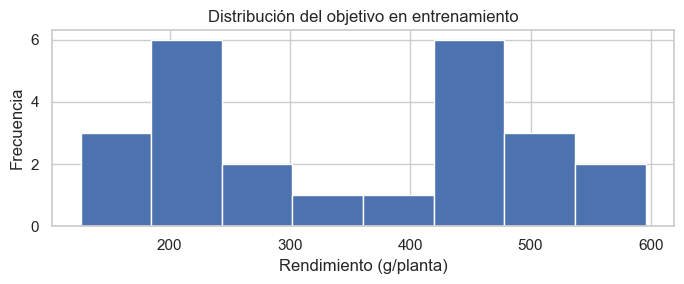

Atípicos IQR (objetivo, train): 0


In [9]:
TARGET = 'yield_g/planta'
assert TARGET in work.columns, f'Objetivo ausente: {TARGET}'
assert not work[['Cultivar','Treatment','Replicate']].duplicated().any()
assert set(tr.Parcel_ID).isdisjoint(set(te.Parcel_ID))
PRED_NUM = list(X_fe_cols)
PRED_CAT = ['Treatment_name', 'Cultivar']
PREDICTORS = PRED_NUM + PRED_CAT
assert TARGET not in PREDICTORS
train_data = tr.loc[tr[TARGET].notna()].copy()
test_data = te.loc[te[TARGET].notna()].copy()
print('Tarea: regresión | objetivo:', TARGET)
print('Train/test:', len(train_data), len(test_data), ' | parcelas:',train_data.Parcel_ID.nunique(),test_data.Parcel_ID.nunique())
print('Predictores numéricos:',len(PRED_NUM),' | categóricos:',PRED_CAT)
print('Faltantes en X train:',int(train_data[PREDICTORS].isna().sum().sum()))
print('Duplicados de clave:',int(work.duplicated(['Cultivar','Treatment','Replicate']).sum()))
print('Objetivo (train):');display(train_data[TARGET].describe().to_frame())
fig,ax=plt.subplots(figsize=(7,3));ax.hist(train_data[TARGET],bins=8,edgecolor='white');ax.set(xlabel='Rendimiento (g/planta)',ylabel='Frecuencia',title='Distribución del objetivo en entrenamiento');plt.tight_layout();plt.show()
# Auditoría descriptiva de atípicos (sin eliminarlos).
q1,q3=train_data[TARGET].quantile([.25,.75]);iqr=q3-q1
print('Atípicos IQR (objetivo, train):',int(((train_data[TARGET]<q1-1.5*iqr)|(train_data[TARGET]>q3+1.5*iqr)).sum()))

## 2. Diseño de evaluación sin fuga de información

- **Train/test**: `GroupShuffleSplit` de la fase anterior, agrupando por parcela; la prueba se consulta solo tras elegir el modelo final.
- **Comparación inicial**: `GroupKFold(4)` en entrenamiento, con exactamente los mismos folds para los seis algoritmos.
- **Selección supervisada de variables**: dentro del `Pipeline`, en cada fold; cuotas científicas de Top 12 (4 suelo, 6 nutrición, 2 RGB). La selección de la fase anterior no se reutiliza como ranking fijo.
- **Preprocesamiento**: imputación, estandarización y OHE dentro del fold. No se emplean variables de producción, calidad del fruto, identificadores o réplicas como predictores.
- **Cautela**: las mediciones de mayo solo justifican interpretación retrospectiva salvo verificación cronológica adicional.

In [10]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import f_regression
from sklearn.model_selection import GroupKFold, GridSearchCV, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.exceptions import ConvergenceWarning
from time import perf_counter
import warnings

# Modificables; no cambiar después de consultar test.
CV_OUTER_FOLDS = 4
CV_INNER_FOLDS = 3
FEATURE_QUOTAS = (4,6,2)
HOLDOUT_EVAL = True  # ejecutar UNA sola vez después de fijar el diseño.

class ScientificSelector(BaseEstimator, TransformerMixin):
    def __init__(self, quotas=(4,6,2), numeric_cols=None, cat_cols=None):
        self.quotas=quotas;self.numeric_cols=numeric_cols;self.cat_cols=cat_cols
    def fit(self,X,y):
        selected=[]
        for prefix,k in zip(('soil','leaf','rgb'),self.quotas):
            if prefix=='soil':cols=[c for c in self.numeric_cols if c.startswith('soil_')]
            elif prefix=='rgb':cols=[c for c in self.numeric_cols if c.startswith(('leaf_rgb_','FE_delta_leaf_rgb_'))]
            else:cols=[c for c in self.numeric_cols if c.startswith(('leaf_','FE_delta_leaf_')) and not c.startswith(('leaf_rgb_','FE_delta_leaf_rgb_'))]
            cols=[c for c in cols if c in X.columns and X[c].notna().any()]
            if not cols or k==0:continue
            z=X[cols].apply(pd.to_numeric,errors='coerce');z=z.fillna(z.median())
            valid=[c for c in cols if z[c].notna().all() and z[c].nunique()>1]
            if not valid:continue
            with warnings.catch_warnings():
                warnings.simplefilter('ignore');scores,_=f_regression(z[valid],np.asarray(y).ravel())
            rank=pd.DataFrame({'feature':valid,'F':np.nan_to_num(scores,nan=-1,posinf=-1,neginf=-1)}).sort_values(['F','feature'],ascending=[False,True])
            selected+=rank.head(k).feature.tolist()
        self.selected_=list(dict.fromkeys(selected))
        if not self.selected_:raise ValueError('Sin predictores numéricos seleccionados.')
        return self
    def transform(self,X):return X.loc[:,self.selected_+self.cat_cols].copy()

def one_hot():
    try:return OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=False)
    except TypeError:return OneHotEncoder(drop='first',handle_unknown='ignore',sparse=False)

def pipeline_for(estimator):
    prep=ColumnTransformer([
        ('numeric',Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())]),make_column_selector(dtype_include=np.number)),
        ('categorical',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('ohe',one_hot())]),PRED_CAT)
    ],sparse_threshold=0)
    return Pipeline([('selector',ScientificSelector(quotas=FEATURE_QUOTAS,numeric_cols=PRED_NUM,cat_cols=PRED_CAT)),('prep',prep),('model',estimator)])

MODELS = {
 'Regresión lineal':LinearRegression(),
 'Ridge':Ridge(alpha=10.0),
 'Lasso':Lasso(alpha=1.0,max_iter=30000,random_state=SEED),
 'SVR':SVR(kernel='rbf',C=1.0,epsilon=0.1, gamma='scale'),
 'KNN':KNeighborsRegressor(n_neighbors=3,weights='uniform'),
 'Árbol de decisión':DecisionTreeRegressor(max_depth=2,min_samples_leaf=3,random_state=SEED),
}
X=train_data[PREDICTORS];y=train_data[TARGET].astype(float);groups=train_data.Parcel_ID
outer_cv=GroupKFold(n_splits=min(CV_OUTER_FOLDS,groups.nunique()))
scoring={'rmse':'neg_root_mean_squared_error','mae':'neg_mean_absolute_error','r2':'r2'}
print('Algoritmos individuales:',list(MODELS))

Algoritmos individuales: ['Regresión lineal', 'Ridge', 'Lasso', 'SVR', 'KNN', 'Árbol de decisión']


## 3. Comparación inicial de seis algoritmos individuales

**Regresión lineal**: referencia sin penalización, vulnerable a multicolinealidad. **Ridge**: penaliza coeficientes grandes. **Lasso**: penalización L1 para simplificación. **SVR**: margen insensible al error y relación no lineal. **KNN**: predicción local por proximidad. **Árbol de decisión**: particiones interpretables con profundidad restringida.

Se registra el tiempo de ajuste de cada fold y las métricas RMSE (principal), MAE y R². El Dummy se reporta solo como referencia, no cuenta entre los seis algoritmos.

,Modelo,RMSE_CV,RMSE_sd,MAE_CV,R2_CV_media,RMSE_train,Tiempo_ajuste_s,Gap_RMSE,Posición
0,KNN,60.085,20.250,48.273,0.825,43.398,0.182,16.687,1
1,Ridge,62.404,4.025,51.194,0.812,38.986,0.206,23.418,2
2,Árbol de decisión,72.558,6.212,58.138,0.751,35.254,0.162,37.304,3
3,Lasso,87.358,31.957,73.080,0.568,19.129,0.215,68.230,4
4,SVR,147.849,12.369,136.314,-0.014,146.812,0.221,1.037,5
5,Regresión lineal,244.262,27.785,228.508,-1.905,4.574,0.166,239.688,6


,Modelo,RMSE_CV,RMSE_sd,MAE_CV,R2_CV_media,RMSE_train,Tiempo_ajuste_s,Gap_RMSE
0,Dummy (media),148.011,13.863,137.446,-0.015,147.859,0.163,0.153


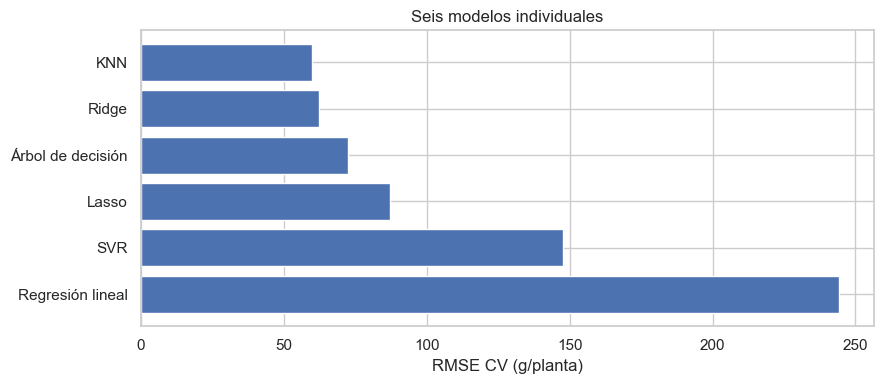

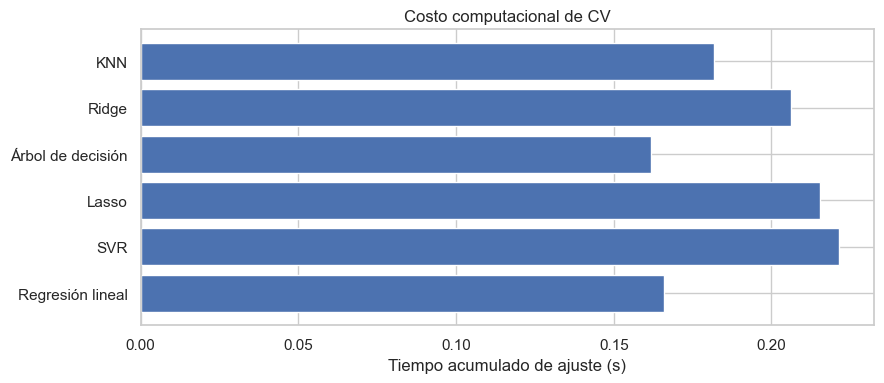

In [11]:
rows=[]
for name,est in [('Dummy (media)',DummyRegressor(strategy='mean')),*MODELS.items()]:
    p=pipeline_for(est)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        result=cross_validate(p,X,y,groups=groups,cv=outer_cv,scoring=scoring,return_train_score=True,return_estimator=False,n_jobs=1,error_score='raise')
    rows.append({'Modelo':name,'RMSE_CV':-result['test_rmse'].mean(), 'RMSE_sd':result['test_rmse'].std(ddof=1),
                 'MAE_CV':-result['test_mae'].mean(),'R2_CV_media':result['test_r2'].mean(),
                 'RMSE_train':-result['train_rmse'].mean(), 'Tiempo_ajuste_s':result['fit_time'].sum(),
                 'Gap_RMSE':(-result['test_rmse'].mean())-(-result['train_rmse'].mean())})
initial=pd.DataFrame(rows)
comparison=initial[initial.Modelo!='Dummy (media)'].sort_values(['RMSE_CV','RMSE_sd']).reset_index(drop=True)
comparison['Posición']=np.arange(1,len(comparison)+1)
display(comparison.round(3));display(initial.loc[initial.Modelo=='Dummy (media)'].round(3))
fig,ax=plt.subplots(figsize=(9,4));ax.barh(comparison.Modelo,comparison.RMSE_CV);ax.invert_yaxis();ax.set(xlabel='RMSE CV (g/planta)',title='Seis modelos individuales');plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(9,4));ax.barh(comparison.Modelo,comparison.Tiempo_ajuste_s);ax.invert_yaxis();ax.set(xlabel='Tiempo acumulado de ajuste (s)',title='Costo computacional de CV');plt.tight_layout();plt.show()
comparison.to_csv(OUT/'avance3_seis_modelos.csv',index=False)

## 4. Selección de los dos candidatos iniciales

Los dos mejores algoritmos se seleccionan **automáticamente por RMSE CV**, sin consultar la prueba. Se documenta estabilidad con desviación del RMSE y brecha train/CV. Con pocas parcelas, el orden puede cambiar al modificar folds; no constituye superioridad estadística definitiva.

In [12]:
top_two=comparison.head(2).Modelo.tolist()
print('Dos modelos seleccionados para optimización:',top_two)
display(comparison.head(2)[['Modelo','RMSE_CV','RMSE_sd','MAE_CV','R2_CV_media','RMSE_train','Gap_RMSE']].round(3))

Dos modelos seleccionados para optimización: ['KNN', 'Ridge']


,Modelo,RMSE_CV,RMSE_sd,MAE_CV,R2_CV_media,RMSE_train,Gap_RMSE
0,KNN,60.085,20.250,48.273,0.825,43.398,16.687
1,Ridge,62.404,4.025,51.194,0.812,38.986,23.418


## 5. Optimización de hiperparámetros (dos modelos)

Se utiliza **GridSearchCV** con `GroupKFold(3)` interno. El espacio de búsqueda incluye regiones de regularización/complexidad pertinentes a *small data*. La búsqueda se aplica al pipeline completo: la selección supervisada, imputación y escalamiento se reajustan en cada fold.

Para evaluar sin confundir la optimización con su propia selección, se estima el desempeño optimizado con **CV anidada**: cada fold externo vuelve a buscar parámetros solo en su parte de entrenamiento. El conjunto de prueba continúa reservado.

**Presupuesto:** se reportan configuraciones, número total de ajustes y tiempo. Los espacios no son universales ni garantizan el óptimo global.

In [13]:
PARAM_GRIDS={
 'Regresión lineal': {'model__fit_intercept':[True,False], 'selector__quotas':[(3,3,2),(4,6,2),(5,8,3)]},
 'Ridge': {'model__alpha':[0.1,1,3,10,30,100,300,1000], 'selector__quotas':[(3,3,2),(4,6,2),(5,8,3),(6,10,4)]},
 'Lasso': {'model__alpha':[0.01,0.03,0.1,0.3,1,3,10,30], 'selector__quotas':[(3,3,2),(4,6,2),(5,8,3),(6,10,4)]},
 'SVR': {'model__C':[0.1,1,10,100], 'model__epsilon':[1,10,30], 'model__gamma':['scale',0.01,0.1], 'selector__quotas':[(4,6,2)]},
 'KNN': {'model__n_neighbors':[2,3,4,5], 'model__weights':['uniform','distance'], 'model__p':[1,2], 'selector__quotas':[(3,3,2),(4,6,2)]},
 'Árbol de decisión': {'model__max_depth':[1,2,3,None], 'model__min_samples_leaf':[2,3,4,5], 'model__ccp_alpha':[0.0,1.0], 'selector__quotas':[(4,6,2)]},
}
# Con pocos datos, una regresión lineal tiene pocos hiperparámetros legítimos.
# No se fabrican 30 combinaciones cuando el algoritmo no las admite.

def search_for(name, X_fit, y_fit, group_fit):
    n=min(CV_INNER_FOLDS,pd.Series(group_fit).nunique())
    if n<3:raise ValueError('Se necesitan al menos tres parcelas para CV interna.')
    search=GridSearchCV(pipeline_for(clone(MODELS[name])),PARAM_GRIDS[name],scoring='neg_root_mean_squared_error',
                        cv=GroupKFold(n_splits=n),n_jobs=1,refit=True,error_score='raise',return_train_score=True)
    t0=perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore',ConvergenceWarning)
        search.fit(X_fit,y_fit,groups=group_fit)
    return search,perf_counter()-t0

# Evaluación anidada de los dos modelos elegidos en el entrenamiento externo.
nested_rows=[]; tuning_rows=[]; searches={}
for name in top_two:
    out_truth=[];out_pred=[];fold_rmse=[];fold_mae=[];fold_r2=[];fold_train=[];fold_times=[]
    for fold,(a,b) in enumerate(outer_cv.split(X,y,groups),start=1):
        X_a,X_b=X.iloc[a],X.iloc[b];y_a,y_b=y.iloc[a],y.iloc[b];g_a=groups.iloc[a]
        search,elapsed=search_for(name,X_a,y_a,g_a)
        pred=np.asarray(search.predict(X_b)).ravel()
        pred_a=np.asarray(search.predict(X_a)).ravel()
        fold_rmse.append(np.sqrt(mean_squared_error(y_b,pred)))
        fold_mae.append(mean_absolute_error(y_b,pred))
        fold_r2.append(r2_score(y_b,pred) if len(y_b)>1 and y_b.nunique()>1 else np.nan)
        fold_train.append(np.sqrt(mean_squared_error(y_a,pred_a)))
        fold_times.append(elapsed)
        nested_rows.append({'Modelo':name,'Fold':fold,'RMSE':fold_rmse[-1],'MAE':fold_mae[-1], 'R2':fold_r2[-1], 'Tiempo_s':elapsed, 'Mejores_parametros':str(search.best_params_)})
    final_search,elapsed=search_for(name,X,y,groups)
    searches[name]=final_search
    tuning_rows.append({'Modelo':name,'RMSE_inicial_CV':float(comparison.set_index('Modelo').loc[name,'RMSE_CV']),
      'RMSE_optimizado_anidado':np.mean(fold_rmse),'RMSE_sd_anidado':np.std(fold_rmse,ddof=1),
      'MAE_optimizado_anidado':np.mean(fold_mae),'R2_media_anidada':np.nanmean(fold_r2),
      'RMSE_train_anidado':np.mean(fold_train),'Configuraciones':len(final_search.cv_results_['params']),
      'Ajustes_internos_full_train':len(final_search.cv_results_['params'])*min(CV_INNER_FOLDS,groups.nunique()),
      'Ajustes_totales_aprox':len(final_search.cv_results_['params'])*(CV_OUTER_FOLDS*CV_INNER_FOLDS+CV_INNER_FOLDS),
      'Mejor_RMSE_CV_interna':-final_search.best_score_, 'Mejores_parametros':str(final_search.best_params_),
      'Tiempo_busqueda_full_train_s':elapsed,'Tiempo_anidado_s':sum(fold_times)})

tuning=pd.DataFrame(tuning_rows).sort_values('RMSE_optimizado_anidado').reset_index(drop=True)
tuning['Cambio_RMSE_vs_inicial']=tuning['RMSE_optimizado_anidado']-tuning['RMSE_inicial_CV']
display(tuning.round(3));display(pd.DataFrame(nested_rows).round(3))
tuning.to_csv(OUT/'avance3_optimizacion.csv',index=False)
pd.DataFrame(nested_rows).to_csv(OUT/'avance3_cv_anidada_folds.csv',index=False)

C:\Users\joaqu\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\joaqu\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\joaqu\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\joaqu\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\joaqu\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Foun

,Modelo,RMSE_inicial_CV,RMSE_optimizado_anidado,RMSE_sd_anidado,MAE_optimizado_anidado,R2_media_anidada,RMSE_train_anidado,Configuraciones,Ajustes_internos_full_train,Ajustes_totales_aprox,Mejor_RMSE_CV_interna,Mejores_parametros,Tiempo_busqueda_full_train_s,Tiempo_anidado_s,Cambio_RMSE_vs_inicial
0,KNN,60.085,63.760,17.767,52.765,0.808,38.445,32,96,480,61.011,"{'model__n_neighbors': 4, 'model__p': 1, 'mode...",5.398,22.309,3.675
1,Ridge,62.404,68.707,11.156,52.533,0.762,30.760,32,96,480,70.188,"{'model__alpha': 10, 'selector__quotas': (5, 8...",6.596,26.318,6.303


,Modelo,Fold,RMSE,MAE,R2,Tiempo_s,Mejores_parametros
0,KNN,1,43.774,38.291,0.883,5.766,"{'model__n_neighbors': 5, 'model__p': 1, 'mode..."
1,KNN,2,73.289,58.197,0.784,5.313,"{'model__n_neighbors': 3, 'model__p': 1, 'mode..."
2,KNN,3,83.167,68.037,0.696,5.793,"{'model__n_neighbors': 3, 'model__p': 1, 'mode..."
3,KNN,4,54.808,46.534,0.868,5.437,"{'model__n_neighbors': 5, 'model__p': 1, 'mode..."
4,Ridge,1,83.749,67.598,0.573,6.521,"{'model__alpha': 3, 'selector__quotas': (4, 6,..."
5,Ridge,2,56.826,40.606,0.870,6.469,"{'model__alpha': 10, 'selector__quotas': (6, 1..."
6,Ridge,3,67.825,57.479,0.798,6.656,"{'model__alpha': 10, 'selector__quotas': (6, 1..."
7,Ridge,4,66.427,44.449,0.807,6.672,"{'model__alpha': 10, 'selector__quotas': (6, 1..."


## 6. Comparación antes y después de optimizar

El RMSE inicial procede de CV simple y el optimizado de CV anidada. **No son estimadores exactamente equivalentes**: la diferencia descriptiva no demuestra por sí sola una mejora atribuible al ajuste. Una comparación estricta antes/después requeriría evaluar también los parámetros iniciales en los mismos folds externos de la CV anidada (se incorpora a continuación).

,Modelo,RMSE_inicial,RMSE_optimizado,Cambio
0,KNN,60.085,63.760,3.675
1,Ridge,62.404,68.707,6.303


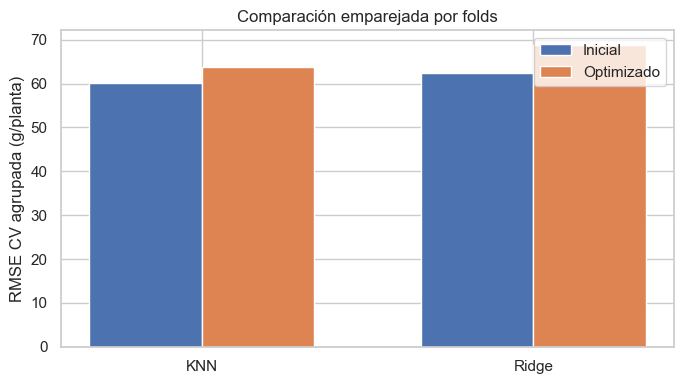

In [14]:
# Comparación emparejada: inicial y optimizado en idénticos folds externos.
paired=[]
for name in top_two:
    for fold,(a,b) in enumerate(outer_cv.split(X,y,groups),start=1):
        base=pipeline_for(clone(MODELS[name]))
        with warnings.catch_warnings():
            warnings.simplefilter('ignore');base.fit(X.iloc[a],y.iloc[a])
        p=np.asarray(base.predict(X.iloc[b])).ravel()
        base_rmse=np.sqrt(mean_squared_error(y.iloc[b],p))
        tuned=float(next(r['RMSE'] for r in nested_rows if r['Modelo']==name and r['Fold']==fold))
        paired.append({'Modelo':name,'Fold':fold,'RMSE_inicial':base_rmse,'RMSE_optimizado':tuned,'Delta_opt_menos_inicial':tuned-base_rmse})
paired_df=pd.DataFrame(paired)
paired_summary=paired_df.groupby('Modelo',as_index=False).agg(RMSE_inicial=('RMSE_inicial','mean'),RMSE_optimizado=('RMSE_optimizado','mean'),Cambio=('Delta_opt_menos_inicial','mean'))
display(paired_summary.round(3))
fig,ax=plt.subplots(figsize=(7,4));xx=np.arange(len(paired_summary));w=.34
ax.bar(xx-w/2,paired_summary.RMSE_inicial,w,label='Inicial');ax.bar(xx+w/2,paired_summary.RMSE_optimizado,w,label='Optimizado');ax.set_xticks(xx,paired_summary.Modelo);ax.set(ylabel='RMSE CV agrupada (g/planta)',title='Comparación emparejada por folds');ax.legend();plt.tight_layout();plt.show()
paired_df.to_csv(OUT/'avance3_antes_despues_folds.csv',index=False)

## 7. Modelo individual final y prueba externa

Se elige el candidato con menor RMSE **optimizado en CV anidada**, utilizando la desviación, la brecha de ajuste y el costo como criterios complementarios. Luego se reentrena en todo el entrenamiento con los hiperparámetros elegidos por búsqueda interna. **Solo entonces** se evalúa el conjunto de prueba una vez. Dado que este proyecto ya examinó el holdout en fases previas, su independencia histórica está limitada; no debe presentarse como validación externa inédita.

Modelo individual elegido: KNN
Mejores hiperparámetros (train): {'model__n_neighbors': 4, 'model__p': 1, 'model__weights': 'uniform', 'selector__quotas': (4, 6, 2)}
RMSE CV anidada: 63.76
Variables numéricas seleccionadas: ['soil_N_microbiano_incubado', 'soil_Microbial_biomass_C_incubado', 'soil_Microbial_biomass_C_sinincubar', 'soil_N _mineral _sinincubar', 'leaf_nut_Mn_March', 'FE_delta_leaf_nut_P', 'leaf_nut_P_March', 'FE_delta_leaf_nut_Ca', 'leaf_nut_Mg_March', 'FE_delta_leaf_nut_Co', 'FE_delta_leaf_rgb_CSI_March_minus_December', 'FE_delta_leaf_rgb_GGA_March_minus_December']


,Modelo,RMSE_test,MAE_test,R2_test,n_test,parcelas_test
0,KNN,57.931,40.85,0.804,8,4


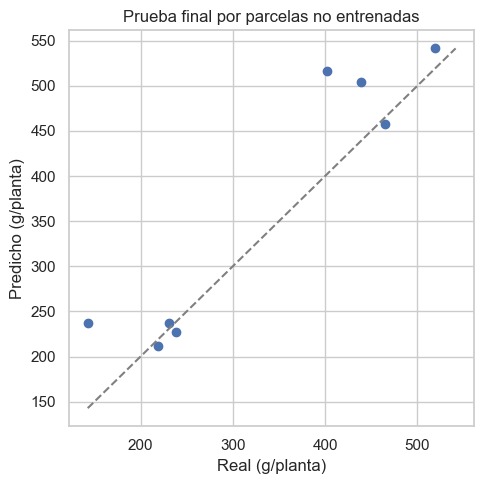

In [15]:
final_name=tuning.iloc[0].Modelo
final_search=searches[final_name]
final_model=final_search.best_estimator_
print('Modelo individual elegido:',final_name)
print('Mejores hiperparámetros (train):',final_search.best_params_)
print('RMSE CV anidada:',round(float(tuning.iloc[0].RMSE_optimizado_anidado),3))
print('Variables numéricas seleccionadas:',final_model.named_steps['selector'].selected_)
if HOLDOUT_EVAL:
    Xt=test_data[PREDICTORS];yt=test_data[TARGET].astype(float)
    yp=np.asarray(final_model.predict(Xt)).ravel()
    final_metrics={'Modelo':final_name,'RMSE_test':np.sqrt(mean_squared_error(yt,yp)),
                   'MAE_test':mean_absolute_error(yt,yp),'R2_test':r2_score(yt,yp) if len(yt)>1 and yt.nunique()>1 else np.nan,
                   'n_test':len(yt),'parcelas_test':test_data.Parcel_ID.nunique()}
    display(pd.DataFrame([final_metrics]).round(3))
    pd.DataFrame([final_metrics]).to_csv(OUT/'avance3_prueba_final.csv',index=False)
    fig,ax=plt.subplots(figsize=(5,5));ax.scatter(yt,yp);lo=min(yt.min(),yp.min());hi=max(yt.max(),yp.max());ax.plot([lo,hi],[lo,hi],linestyle='--',color='gray');ax.set(xlabel='Real (g/planta)',ylabel='Predicho (g/planta)',title='Prueba final por parcelas no entrenadas');plt.tight_layout();plt.show()
else:
    print('Prueba reservada: HOLDOUT_EVAL=False')

## 8. Interpretación, limitaciones y conclusiones reproducibles

Se presenta una síntesis calculada de los resultados reales. La importancia de variables para modelos lineales puede examinarse mediante coeficientes, pero su estabilidad requiere remuestreo; la selección de características no implica causalidad. La comparación de seis modelos y la optimización se circunscriben al rendimiento, no a todos los objetivos de Nancy.

In [16]:
dummy_rmse=float(initial.loc[initial.Modelo=='Dummy (media)','RMSE_CV'].iloc[0])
selected_rmse=float(tuning.iloc[0].RMSE_optimizado_anidado)
print('RESUMEN AUTOMATICO')
print('Mejor modelo individual:',final_name)
print('RMSE de Dummy (CV simple):',round(dummy_rmse,3))
print('RMSE del elegido (CV anidada):',round(selected_rmse,3))
print('Mejora descriptiva frente a Dummy (%):',round(100*(dummy_rmse-selected_rmse)/dummy_rmse,2))
print('Nota: estimadores con distinta estrategia de selección; la mejora es descriptiva.')
print('Limitaciones: 16 parcelas, dependencia intra-parcela, selección exploratoria de candidatos, mediciones temporales retrospectivas.')
print('No se afirma óptimo global ni superioridad causal de tratamientos.')

RESUMEN AUTOMATICO
Mejor modelo individual: KNN
RMSE de Dummy (CV simple): 148.011
RMSE del elegido (CV anidada): 63.76
Mejora descriptiva frente a Dummy (%): 56.92
Nota: estimadores con distinta estrategia de selección; la mejora es descriptiva.
Limitaciones: 16 parcelas, dependencia intra-parcela, selección exploratoria de candidatos, mediciones temporales retrospectivas.
No se afirma óptimo global ni superioridad causal de tratamientos.


## 9. Lista de comprobación de requisitos

| Requisito | Evidencia |
|---|---|
| Seis modelos individuales | Tabla `comparison` (Linear, Ridge, Lasso, SVR, KNN, Árbol) |
| Sin ensambles | Ninguno de los seis algoritmos usa bagging, boosting ni votación |
| Tres métricas y tiempo | RMSE, MAE, R², segundos de ajuste |
| Dos mejores candidatos | `top_two` seleccionados por CV |
| Optimización amplia | `GridSearchCV` con espacios y número de ajustes reportados |
| Comparación antes/después | `paired_summary` en los mismos folds externos |
| Un único modelo final | `final_name` y evaluación de prueba controlada |
| Reproducibilidad | semilla 54, splits agrupados, pipeline completo |
| Limitaciones | tamaño muestral, optimismo de selección y fechas |

**Pendiente de validación científica:** confirmar con Nancy si el objetivo principal debe ser rendimiento o alguno de los indicadores de calidad nutricional. Para otros objetivos se debe repetir el diseño, no reutilizar los mejores parámetros de rendimiento.

## Declaración de uso de inteligencia artificial

Se utilizaron herramientas de inteligencia artificial generativa (ChatGPT de OpenAI) como apoyo para estructurar la libreta, proponer código Python, documentar decisiones metodológicas y revisar riesgos de fuga de información y sobreajuste. La ejecución, verificación de resultados, interpretación científica y responsabilidad sobre las conclusiones corresponden al equipo. No se atribuyen a la herramienta mediciones experimentales ni se presentan resultados no calculados.